# Reproducible review of saved aggregate results
**Bhakti Doshi | Synthetic Delaware EHR portfolio**

This notebook runs without the original CSVs. It recomputes descriptive estimates and statistical comparisons from counts saved in the supplied assessment notebook. It **does not reproduce the raw-data preparation or refit individual-level regression models**. Labels are corrected to the intervals the original code actually used: 8-19, 20-29 and 30-40 distinct condition descriptions.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.analysis import *
plt.rcParams.update({'figure.figsize': (9, 5), 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})


In [2]:
sex=pd.read_csv(ROOT/'data/aggregates/sex_by_condition.csv')
cohorts=pd.read_csv(ROOT/'data/aggregates/cohorts.csv')
cohorts['death_pct']=100*cohorts.deaths/cohorts.n
display(cohorts)
assert sex.n.sum()==1716 and sex.deaths.sum()==231


,cohort,n,deaths,death_pct
0,Full export,1753,253,14.432402
1,8-40 descriptions,1716,231,13.461538
2,Excluded,37,22,59.459459


## Death proportions and confidence intervals
The restricted cohort excludes 37 records, including 22 recorded deaths. This removes 2.11% of records but 8.70% of deaths. The death proportion changes from 14.43% to 13.46%, a decline of 0.97 **percentage points**. Restriction therefore needs a sensitivity analysis, not an assumption that robustness improved.


,condition_group,n,deaths,death_pct,ci_low_pct,ci_high_pct
0,8-19,740,83,11.216216,9.139917,13.693102
1,20-29,749,95,12.683578,10.489179,15.258800
2,30-40,227,53,23.348018,18.316243,29.266830


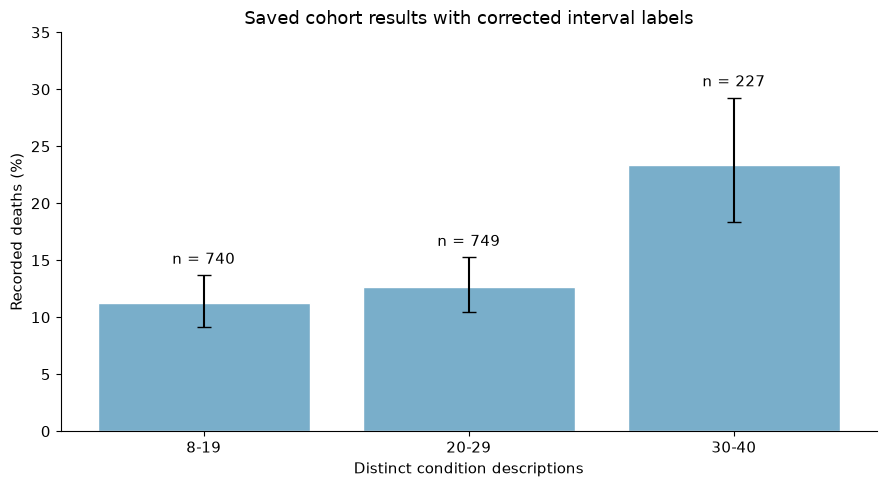

In [3]:
burden=sex.groupby('condition_group',sort=False)[['n','deaths']].sum().reset_index()
for table in [burden,sex]:
    table['death_pct']=100*table.deaths/table.n
    bounds=[wilson_ci(d,n) for d,n in zip(table.deaths,table.n)]
    table['ci_low_pct']=[100*b[0] for b in bounds]; table['ci_high_pct']=[100*b[1] for b in bounds]
display(burden)
fig,ax=plt.subplots()
ax.bar(burden.condition_group,burden.death_pct,color='#79aeca',edgecolor='white',
    yerr=np.vstack([burden.death_pct-burden.ci_low_pct,burden.ci_high_pct-burden.death_pct]),capsize=5)
for i,r in burden.iterrows(): ax.text(i,r.ci_high_pct+1,f'n = {r.n}',ha='center')
ax.set(xlabel='Distinct condition descriptions',ylabel='Recorded deaths (%)',ylim=(0,35),title='Saved cohort results with corrected interval labels')
fig.tight_layout(); (ROOT/'figures').mkdir(exist_ok=True)
fig.savefig(ROOT/'figures/burden.png',dpi=180); plt.show()


## Sex comparisons with correct Holm adjustment
The original hand-written Holm procedure enforced monotonicity in the wrong direction. The standard implementation is used here. These are ratios of observed death proportions. They do not estimate a causal effect or a time-standardised mortality rate.


,group,ratio,ci_low,ci_high,p_value,test,continuity_correction,p_holm
0,8-19,1.805282,1.181439,2.758537,0.005369,Pearson chi-square,False,0.016108
1,20-29,1.578082,1.074181,2.318364,0.018698,Pearson chi-square,False,0.037396
2,30-40,1.728000,1.033427,2.889399,0.031596,Pearson chi-square,False,0.037396


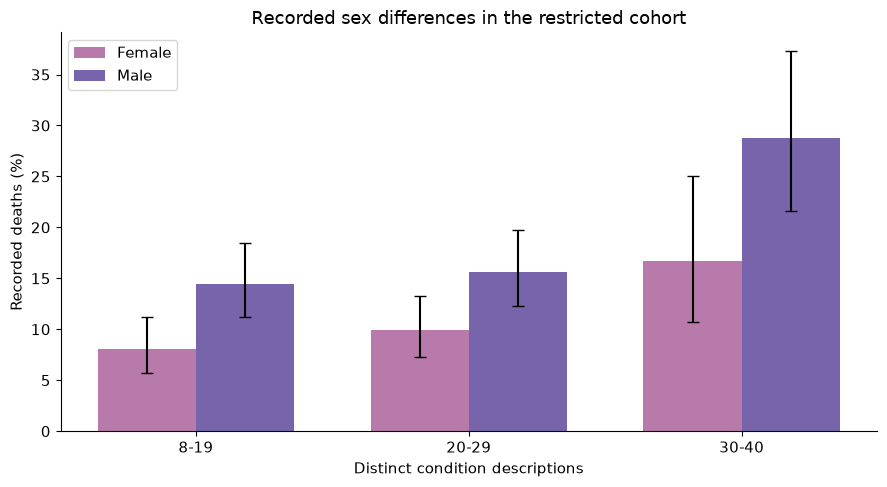

In [4]:
rows=[]
for label,g in sex.groupby('condition_group',sort=False):
    f=g[g.sex.eq('Female')].iloc[0]; m=g[g.sex.eq('Male')].iloc[0]
    rows.append({'group':label,**compare_sexes(int(f.n),int(f.deaths),int(m.n),int(m.deaths))})
comparisons=pd.DataFrame(rows)
comparisons['p_holm']=holm_adjust(comparisons.p_value)
display(comparisons)
comparisons.to_csv(ROOT/'data/aggregates/recomputed_sex_comparisons.csv',index=False)
fig,ax=plt.subplots()
x=np.arange(3)
for offset,label,color in [(-.18,'Female','#b77aaa'),(.18,'Male','#7764aa')]:
    g=sex[sex.sex.eq(label)]
    ax.bar(x+offset,g.death_pct,width=.36,label=label,color=color,
        yerr=np.vstack([g.death_pct-g.ci_low_pct,g.ci_high_pct-g.death_pct]),capsize=4)
ax.set(xticks=x,xticklabels=CONDITION_LABELS,xlabel='Distinct condition descriptions',ylabel='Recorded deaths (%)',title='Recorded sex differences in the restricted cohort')
ax.legend(); fig.tight_layout(); fig.savefig(ROOT/'figures/sex_comparison.png',dpi=180); plt.show()


## Sparse groups
Zero observed deaths are compatible with nonzero uncertainty. The original figure hid the interval for the youngest high-burden group. Its Wilson interval is approximately 0% to 49%, based on only four records. Age groups reflect the original run's changing reference date, which was not recorded.


,age_group,condition_group,n,deaths,death_pct,ci_low_pct,ci_high_pct
0,20-39,8-19,198,7,3.535354,1.722887,7.116456
1,20-39,20-29,77,2,2.597403,0.715216,8.984583
2,20-39,30-40,4,0,0.000000,0.000000,48.989084
3,40-59,8-19,373,29,7.774799,5.467612,10.942859
4,40-59,20-29,293,17,5.802048,3.653724,9.094312
5,40-59,30-40,62,11,17.741935,10.206438,29.041567
6,60-79,8-19,169,47,27.810651,21.605793,35.001840
7,60-79,20-29,379,76,20.052770,16.331254,24.375272
8,60-79,30-40,161,42,26.086957,19.917825,33.370625


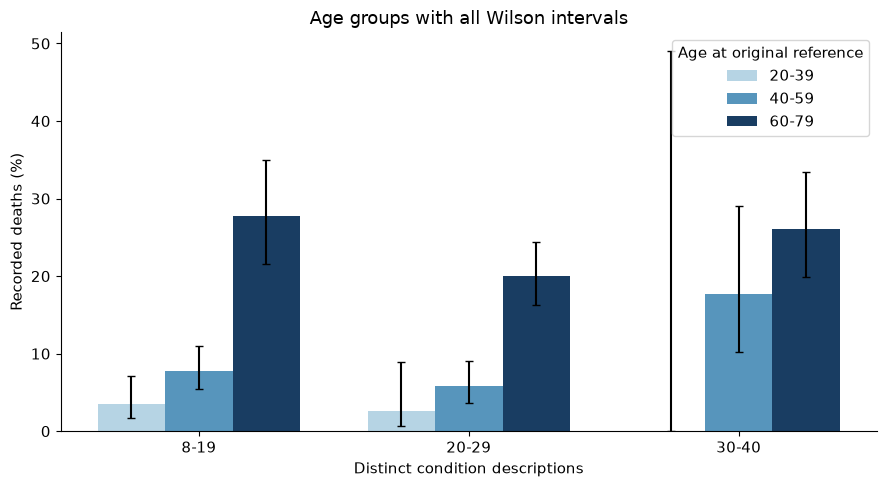

In [5]:
age=pd.read_csv(ROOT/'data/aggregates/age_by_condition.csv')
age['death_pct']=100*age.deaths/age.n
bounds=[wilson_ci(d,n) for d,n in zip(age.deaths,age.n)]
age['ci_low_pct']=[100*b[0] for b in bounds]; age['ci_high_pct']=[100*b[1] for b in bounds]
display(age)
fig,ax=plt.subplots()
for offset,label,color in [(-.25,'20-39','#b6d4e4'),(0,'40-59','#5795bc'),(.25,'60-79','#193d62')]:
    g=age[age.age_group.eq(label)]
    ax.bar(x+offset,g.death_pct,width=.25,label=label,color=color,
        yerr=np.vstack([g.death_pct-g.ci_low_pct,g.ci_high_pct-g.death_pct]),capsize=3)
ax.set(xticks=x,xticklabels=CONDITION_LABELS,ylabel='Recorded deaths (%)',xlabel='Distinct condition descriptions',title='Age groups with all Wilson intervals')
ax.legend(title='Age at original reference'); fig.tight_layout(); fig.savefig(ROOT/'figures/age_comparison.png',dpi=180); plt.show()


## Regression evidence and interpretation
The original saved output reports an age/sex-adjusted male-versus-female odds ratio of **1.835** (95% CI 1.362-2.472), and an interaction odds ratio of **0.99552** (95% CI 0.95115-1.04196), **p = 0.846943**. The essay's interaction p = 0.74 does not match the notebook.

These values are historical outputs, not newly fitted estimates. The interaction result provides insufficient evidence that the sex association changes with condition count on the log-odds scale. It does not demonstrate a constant effect or reveal mechanisms. The data do not establish that severity, behaviour or physiological reserve explains the difference.

The original fully adjusted model had an inverse condition-count coefficient (OR 0.909), alongside positive medication and encounter coefficients. This may reflect correlated retrospective histories or conditioning effects, and is not evidence that additional diagnoses protect patients.

The [corrected raw-data notebook](assessment.ipynb) uses the included extracts and a fixed observed-date cutoff. See that notebook and the revised report for the rerun results.
